<h2 align="center" style="color:blue">IMPORTING LIBRARY</h2>

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets,transforms,models
from torch.utils.data import DataLoader,random_split
from matplotlib import pyplot as plt
from sklearn.metrics import classification_report,confusion_matrix,ConfusionMatrixDisplay
import optuna

In [4]:
device= torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


<h2 align="center" style="color:blue">LOAD DATASETS</h2>

In [5]:
transform=transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2,contrast=0.2,saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [6]:
dataset=datasets.ImageFolder(root='./dataset',transform=transform)
len(dataset)

2300

In [7]:
class_names=dataset.classes

In [8]:
num_clases=len(class_names)
num_clases

6

In [9]:
train_size=int(len(dataset)*0.75)
test_size=int(len(dataset) -train_size)
train_size,test_size

(1725, 575)

In [10]:
train_dataset,test_dataset=random_split(dataset,[train_size, test_size])

In [11]:
train_dataloader=DataLoader(train_dataset,batch_size=32,shuffle=True)
test_dataloader=DataLoader(test_dataset,batch_size=32,shuffle=True)

In [12]:
for images,labels in train_dataloader:
    print(images.shape)
    print(labels.shape)
    break

torch.Size([32, 3, 224, 224])
torch.Size([32])


In [13]:
labels[1]

tensor(3)

In [14]:
images[1].shape

torch.Size([3, 224, 224])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


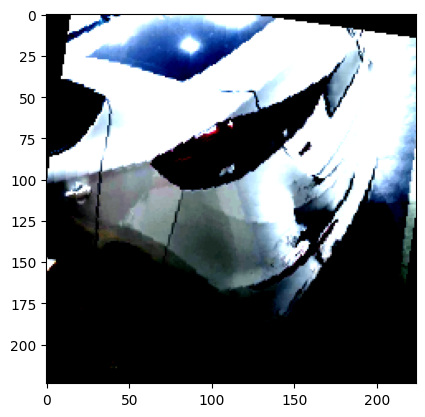

In [15]:
plt.imshow(images[1].permute(1,2,0))
plt.show()

<h2 align="center" style="color:blue">MODEL TRAINING USING CNN</h2>

In [16]:
class CARClassifierCNN(nn.Module):
    def __init__(self,num_clases):
        super().__init__()
        self.network=nn.Sequential(
            nn.Conv2d(in_channels=3,out_channels=16,kernel_size=(3,3),padding='same',stride=(1,1)),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2),stride=(2,2),padding=0),
            nn.Conv2d(in_channels=16,out_channels=32,kernel_size=(3,3),padding='same',stride=(1,1)),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2),stride=(2,2),padding=0),
            nn.Conv2d(in_channels=32,out_channels=64,kernel_size=(3,3),padding='same',stride=(1,1)),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2),stride=(2,2),padding=0),
            nn.Flatten(),
            nn.Linear(28*28*64,512),
            nn.ReLU(),
            nn.Linear(512,num_clases)
        )
    def forward(self,x):
        return self.network(x)

In [17]:
model=CARClassifierCNN(num_clases=num_clases).to(device)
loss_fn=nn.CrossEntropyLoss().to(device)
optimizer=optim.Adam(model.parameters(),lr=0.001)

In [18]:
def train_model(model,optimizer,loss_fn,epochs=5):

    for epoch in range(epochs):
        model.train()
        running_loss=0.0
        for batch,(images,labels) in enumerate(train_dataloader):
            images=images.to(device)
            labels=labels.to(device)
        
        #Zero Parameter Gradients
            optimizer.zero_grad()

        #Forward Pass
            outputs=model(images)
            loss=loss_fn(outputs,labels)
        #Backward Pass & Optimization    
            loss.backward()
            optimizer.step()

            if (batch+1) % 10 == 0:
                print(f"Batch: {batch+1}, Epoch: {epoch+1}, Loss: {loss.item():0.2f}")

            running_loss+= loss.item()*images.size(0)

        epoch_loss= running_loss/len(train_dataloader.dataset)   
        print(f"Epoch [{epoch+1}/{epochs}], Avg Loss: {epoch_loss:.4f}")    

        #Validation
        model.eval()
        correct=0
        total=0
        true_labels=[]
        predicted_labels=[]

        with torch.no_grad():
            for images,labels in test_dataloader:
                images=images.to(device)
                labels=labels.to(device)
                outputs=model(images)
                _,predicted=torch.max(outputs.data,1)

                total+=labels.size(0)
                correct+=(predicted==labels).sum().item()

                true_labels.extend(labels.cpu().numpy())
                predicted_labels.extend(predicted.cpu().numpy())
            print(f"*** Validation Accuracy: {100 * correct / total:.2f}% ***")

    return true_labels,predicted_labels

In [19]:
true_labels, predicted_labels = train_model(model, optimizer=optimizer, loss_fn=loss_fn, epochs=10)

Batch: 10, Epoch: 1, Loss: 1.90
Batch: 20, Epoch: 1, Loss: 1.78
Batch: 30, Epoch: 1, Loss: 1.68
Batch: 40, Epoch: 1, Loss: 1.51
Batch: 50, Epoch: 1, Loss: 1.54
Epoch [1/10], Avg Loss: 1.9490
*** Validation Accuracy: 37.57% ***
Batch: 10, Epoch: 2, Loss: 1.48
Batch: 20, Epoch: 2, Loss: 1.44
Batch: 30, Epoch: 2, Loss: 1.42
Batch: 40, Epoch: 2, Loss: 1.27
Batch: 50, Epoch: 2, Loss: 1.21
Epoch [2/10], Avg Loss: 1.4865
*** Validation Accuracy: 44.00% ***
Batch: 10, Epoch: 3, Loss: 1.23
Batch: 20, Epoch: 3, Loss: 1.51
Batch: 30, Epoch: 3, Loss: 1.70
Batch: 40, Epoch: 3, Loss: 1.08
Batch: 50, Epoch: 3, Loss: 1.55
Epoch [3/10], Avg Loss: 1.3425
*** Validation Accuracy: 47.83% ***
Batch: 10, Epoch: 4, Loss: 1.14
Batch: 20, Epoch: 4, Loss: 1.53
Batch: 30, Epoch: 4, Loss: 0.95
Batch: 40, Epoch: 4, Loss: 1.22
Batch: 50, Epoch: 4, Loss: 1.22
Epoch [4/10], Avg Loss: 1.1565
*** Validation Accuracy: 50.61% ***
Batch: 10, Epoch: 5, Loss: 0.94
Batch: 20, Epoch: 5, Loss: 1.02
Batch: 30, Epoch: 5, Loss: 0

<h2 align="center" style="color:blue">MODEL TRAINING USING CNN WITH REGULARIZATION</h2>

In [20]:
class CARClassifierCNNWithRegularization(nn.Module):
    def __init__(self,num_clases):
        super().__init__()
        self.network=nn.Sequential(
            nn.Conv2d(in_channels=3,out_channels=16,kernel_size=(3,3),padding='same',stride=(1,1)),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2),stride=(2,2),padding=0),
            nn.Conv2d(in_channels=16,out_channels=32,kernel_size=(3,3),padding='same',stride=(1,1)),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2),stride=(2,2),padding=0),
            nn.Conv2d(in_channels=32,out_channels=64,kernel_size=(3,3),padding='same',stride=(1,1)),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2),stride=(2,2),padding=0),
            nn.Flatten(),
            nn.Linear(28*28*64,512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512,num_clases)
        )
    def forward(self,x):
        return self.network(x)

In [21]:
model=CARClassifierCNNWithRegularization(num_clases=num_clases).to(device)
loss_fn=nn.CrossEntropyLoss().to(device)
optimizer=optim.Adam(model.parameters(),lr=0.001,weight_decay=1e-4)

true_labels, predicted_labels = train_model(model, optimizer=optimizer, loss_fn=loss_fn, epochs=10)

Batch: 10, Epoch: 1, Loss: 9.55
Batch: 20, Epoch: 1, Loss: 7.98
Batch: 30, Epoch: 1, Loss: 3.42
Batch: 40, Epoch: 1, Loss: 1.80
Batch: 50, Epoch: 1, Loss: 1.71
Epoch [1/10], Avg Loss: 8.4325
*** Validation Accuracy: 42.43% ***
Batch: 10, Epoch: 2, Loss: 1.38
Batch: 20, Epoch: 2, Loss: 1.49
Batch: 30, Epoch: 2, Loss: 1.47
Batch: 40, Epoch: 2, Loss: 1.18
Batch: 50, Epoch: 2, Loss: 1.32
Epoch [2/10], Avg Loss: 1.3816
*** Validation Accuracy: 48.87% ***
Batch: 10, Epoch: 3, Loss: 1.19
Batch: 20, Epoch: 3, Loss: 1.41
Batch: 30, Epoch: 3, Loss: 1.23
Batch: 40, Epoch: 3, Loss: 1.16
Batch: 50, Epoch: 3, Loss: 1.10
Epoch [3/10], Avg Loss: 1.2576
*** Validation Accuracy: 46.96% ***
Batch: 10, Epoch: 4, Loss: 1.27
Batch: 20, Epoch: 4, Loss: 1.44
Batch: 30, Epoch: 4, Loss: 1.32
Batch: 40, Epoch: 4, Loss: 1.17
Batch: 50, Epoch: 4, Loss: 1.27
Epoch [4/10], Avg Loss: 1.2162
*** Validation Accuracy: 48.87% ***
Batch: 10, Epoch: 5, Loss: 1.10
Batch: 20, Epoch: 5, Loss: 1.32
Batch: 30, Epoch: 5, Loss: 1

<h2 align="center" style="color:blue">TRANSFER LEARNING FROM EFFICIENTNET</h2>

In [22]:
class CARClassifierEfficientNet(nn.Module):
    def __init__(self,num_clases):
        super().__init__()
        self.model=models.efficientnet_b0(weights='DEFAULT')
        for params in self.model.parameters():
            params.requires_grad=False
        in_features = self.model.classifier[1].in_features

        self.model.classifier= nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(in_features,num_clases)
        )
    def forward(self,x):
        x=self.model(x)
        return x    

In [23]:
model=CARClassifierEfficientNet(num_clases=num_clases).to(device)
loss_fn=nn.CrossEntropyLoss().to(device)
optimizer=optim.Adam(filter(lambda p: p.requires_grad,model.parameters()),lr=0.001,weight_decay=1e-4)

true_labels, predicted_labels = train_model(model, optimizer=optimizer, loss_fn=loss_fn, epochs=10)

Batch: 10, Epoch: 1, Loss: 1.64
Batch: 20, Epoch: 1, Loss: 1.56
Batch: 30, Epoch: 1, Loss: 1.46
Batch: 40, Epoch: 1, Loss: 1.32
Batch: 50, Epoch: 1, Loss: 1.14
Epoch [1/10], Avg Loss: 1.4804
*** Validation Accuracy: 56.17% ***
Batch: 10, Epoch: 2, Loss: 1.22
Batch: 20, Epoch: 2, Loss: 1.06
Batch: 30, Epoch: 2, Loss: 1.13
Batch: 40, Epoch: 2, Loss: 1.14
Batch: 50, Epoch: 2, Loss: 1.04
Epoch [2/10], Avg Loss: 1.1492
*** Validation Accuracy: 59.30% ***
Batch: 10, Epoch: 3, Loss: 1.05
Batch: 20, Epoch: 3, Loss: 1.01
Batch: 30, Epoch: 3, Loss: 0.95
Batch: 40, Epoch: 3, Loss: 0.78
Batch: 50, Epoch: 3, Loss: 0.97
Epoch [3/10], Avg Loss: 1.0397
*** Validation Accuracy: 60.17% ***
Batch: 10, Epoch: 4, Loss: 0.92
Batch: 20, Epoch: 4, Loss: 0.90
Batch: 30, Epoch: 4, Loss: 1.06
Batch: 40, Epoch: 4, Loss: 0.92
Batch: 50, Epoch: 4, Loss: 0.86
Epoch [4/10], Avg Loss: 0.9822
*** Validation Accuracy: 64.87% ***
Batch: 10, Epoch: 5, Loss: 1.00
Batch: 20, Epoch: 5, Loss: 0.95
Batch: 30, Epoch: 5, Loss: 0

<h2 align="center" style="color:blue">TRANSFER LEARNING FROM RESNET</h2>

In [24]:
class CARClassifierResNet(nn.Module):
    def __init__(self,num_clases,dropout_rate):
        super().__init__()
        self.model=models.resnet50(weights='DEFAULT')
        for params in self.model.parameters():
            params.requires_grad=False

        for params in self.model.layer4.parameters():
            params.requires_grad=True 
               
        in_features = self.model.fc.in_features

        self.model.fc= nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(in_features,num_clases)
        )
    def forward(self,x):
        x=self.model(x)
        return x    

In [25]:
model=CARClassifierResNet(num_clases=num_clases,dropout_rate=0.5).to(device)
loss_fn=nn.CrossEntropyLoss().to(device)
optimizer=optim.Adam(filter(lambda p: p.requires_grad,model.parameters()),lr=0.001,weight_decay=1e-4)

true_labels, predicted_labels = train_model(model, optimizer=optimizer, loss_fn=loss_fn, epochs=10)

Batch: 10, Epoch: 1, Loss: 1.00
Batch: 20, Epoch: 1, Loss: 0.78
Batch: 30, Epoch: 1, Loss: 1.10
Batch: 40, Epoch: 1, Loss: 0.83
Batch: 50, Epoch: 1, Loss: 0.71
Epoch [1/10], Avg Loss: 0.9145
*** Validation Accuracy: 72.70% ***
Batch: 10, Epoch: 2, Loss: 0.64
Batch: 20, Epoch: 2, Loss: 0.46
Batch: 30, Epoch: 2, Loss: 0.68
Batch: 40, Epoch: 2, Loss: 0.40
Batch: 50, Epoch: 2, Loss: 0.79
Epoch [2/10], Avg Loss: 0.5563
*** Validation Accuracy: 74.96% ***
Batch: 10, Epoch: 3, Loss: 0.36
Batch: 20, Epoch: 3, Loss: 0.53
Batch: 30, Epoch: 3, Loss: 0.35
Batch: 40, Epoch: 3, Loss: 0.43
Batch: 50, Epoch: 3, Loss: 0.53
Epoch [3/10], Avg Loss: 0.4136
*** Validation Accuracy: 76.00% ***
Batch: 10, Epoch: 4, Loss: 0.18
Batch: 20, Epoch: 4, Loss: 0.42
Batch: 30, Epoch: 4, Loss: 0.25
Batch: 40, Epoch: 4, Loss: 0.22
Batch: 50, Epoch: 4, Loss: 0.26
Epoch [4/10], Avg Loss: 0.3137
*** Validation Accuracy: 73.39% ***
Batch: 10, Epoch: 5, Loss: 0.26
Batch: 20, Epoch: 5, Loss: 0.14
Batch: 30, Epoch: 5, Loss: 0

<h2 align="center" style="color:blue">AFTER HYPERPARAMETER TUNNING</h2>

In [35]:
model=CARClassifierResNet(num_clases=num_clases,dropout_rate=0.5540362888980227).to(device)
loss_fn=nn.CrossEntropyLoss().to(device)
optimizer=optim.Adam(filter(lambda p: p.requires_grad,model.parameters()),lr=0.0006358358856676254,weight_decay=1e-4)

true_labels, predicted_labels = train_model(model, optimizer=optimizer, loss_fn=loss_fn, epochs=10)

Batch: 10, Epoch: 1, Loss: 1.30
Batch: 20, Epoch: 1, Loss: 1.08
Batch: 30, Epoch: 1, Loss: 0.46
Batch: 40, Epoch: 1, Loss: 0.55
Batch: 50, Epoch: 1, Loss: 0.52
Epoch [1/10], Avg Loss: 0.9511
*** Validation Accuracy: 71.65% ***
Batch: 10, Epoch: 2, Loss: 0.41
Batch: 20, Epoch: 2, Loss: 0.49
Batch: 30, Epoch: 2, Loss: 0.67
Batch: 40, Epoch: 2, Loss: 0.55
Batch: 50, Epoch: 2, Loss: 0.43
Epoch [2/10], Avg Loss: 0.5449
*** Validation Accuracy: 74.26% ***
Batch: 10, Epoch: 3, Loss: 0.51
Batch: 20, Epoch: 3, Loss: 0.39
Batch: 30, Epoch: 3, Loss: 0.15
Batch: 40, Epoch: 3, Loss: 0.34
Batch: 50, Epoch: 3, Loss: 0.56
Epoch [3/10], Avg Loss: 0.3818
*** Validation Accuracy: 69.91% ***
Batch: 10, Epoch: 4, Loss: 0.49
Batch: 20, Epoch: 4, Loss: 0.24
Batch: 30, Epoch: 4, Loss: 0.23
Batch: 40, Epoch: 4, Loss: 0.50
Batch: 50, Epoch: 4, Loss: 0.36
Epoch [4/10], Avg Loss: 0.3192
*** Validation Accuracy: 75.48% ***
Batch: 10, Epoch: 5, Loss: 0.13
Batch: 20, Epoch: 5, Loss: 0.38
Batch: 30, Epoch: 5, Loss: 0

<h2 align="center" style="color:blue">MODEL EVALUATION </h2>

In [36]:
report = classification_report(true_labels, predicted_labels)
print(report)

              precision    recall  f1-score   support

           0       0.75      0.95      0.84       133
           1       0.90      0.60      0.72       122
           2       0.85      0.89      0.87       121
           3       0.81      0.63      0.71        62
           4       0.65      0.79      0.71        70
           5       0.79      0.81      0.80        67

    accuracy                           0.79       575
   macro avg       0.79      0.78      0.78       575
weighted avg       0.80      0.79      0.79       575



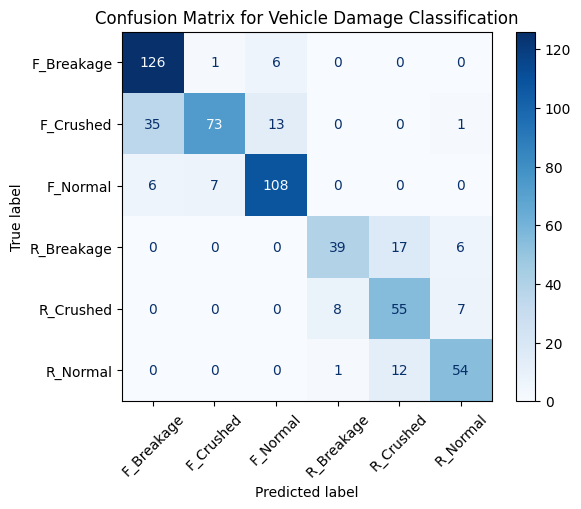

In [37]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from matplotlib import pyplot as plt

conf_matrix = confusion_matrix(true_labels, predicted_labels, labels=np.arange(num_clases))
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix for Vehicle Damage Classification")
plt.show()

<h2 align="center" style="color:blue">SAVING MODEL</h2>

In [38]:
torch.save(model.state_dict(), 'saved_model.pth')